In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv('data-kejadian-kebakaran-di-provinsi-dki-jakarta-tahun-2013-komponen-data.xls.csv')

In [3]:
df

,periode_data,tanggal,keterangan_jkb,sumber_informasi,waktu_informasi,alamat_kejadian,rt,rw,kelurahan,kecamatan,...,objek_bp,objek_bup,objek_bi,objek_kd,objek_ln,jumlah_kk,jumlah_jiwa,taksiran_kerugian,kronologis_kejadian,keterangan
0,2013,09/JULI/2013 (SELASA),BENCANA KEBAKARAN,MASYARAKAT,17:45,JL. MENCENG RAYA NO.39,3,11,TEGAL ALUR,KALIDERES,...,-,-,-,-,1,0.0,0.0,"15,000,000",AKIBAT TERJADI HAWA PANAS DIDALAM TANGKI YANG ...,NaN
1,2013,11/JULI/2013 (KAMIS),BENCANA KEBAKARAN,MASYARAKAT,18:30,JL KAZA,1,11,KELAPA DUA WETAN,CIRACAS,...,1,-,-,-,-,1.0,4.0,"2,000,000",KORSLETING LISTRIK PADA KIPAS ANGIN HINGGA MEN...,NaN
2,2013,12/JULI/2013 (JUMAT),PERTOLONGAN GAWAT DARURAT (AMBULAN TRANSPORTASI).,PETUGAS INSTANSI LAIN,21:30,JL. YOS SUDARSO / TOL PRIOK - SOEKARNO HATTA,NaN,NaN,TANJUNG PRIOK,TANJUNG PRIOK,...,-,-,-,-,1,0.0,0.0,-,AKIBAT MENGEREM MENDADAK SEHINGGA TRUK CONTAIN...,NaN
3,2013,16/JULI/2013 (SELASA),BENCANA KEBAKARAN,PETUGAS INSTANSI LAIN,13:45,JL. RAWA BAMBU,5,13,PASAR MINGGU,PASAR MINGGU,...,-,-,-,-,1,0.0,0.0,"1,000,000","TERJADI KONSLETING PADA KABEL UDARA PLN, SEHIN...",NaN
4,2013,17/JULI/2013 (RABU),BENCANA KEBAKARAN,MASYARAKAT,16:00,"JL. NEPTUNUS, VILLA CINERE MAS NO.35",NaN,NaN,DEPOK,DEPOK,...,NaN,NaN,NaN,NaN,1,NaN,NaN,"100,000","AKIBAT SELANG REGULATOR BOCOR, SEHINGGA TIMBUL...",NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1587,2013,15/DESEMBER/2013 (MINGGU),BENCANA KEBAKARAN,MASYARAKAT,5:25,JL. RAYA TELUK GONG,6,9,PENJARINGAN,PENJARINGAN,...,-,1,-,-,-,1.0,3.0,"15,000,000",DIDUGA BERASAL DARI HUBUNGAN ARUS PENDEK YANG ...,NaN
1588,2013,17/DESEMBER/2013 (SELASA),BENCANA KEBAKARAN,PETUGAS PEMADAM,21:10,JL. SAWAH LUNTO NO.1,2,13,PASAR MANGGIS,SETIABUDI,...,-,-,-,-,1,NaN,NaN,"2,000,000",DIDUGA DARI HUBUNGAN SINGKAT ARUS PENDEK LISTR...,NaN
1589,2013,23/DESEMBER/2013 (SENIN),BENCANA KEBAKARAN,MASYARAKAT,23:45,JL. KEMAYORAN GEMPOL,12,3,KEBON KOSONG,KEMAYORAN,...,-,-,-,-,1,NaN,NaN,"5,000,000",DIDUGA TERJADI KORSLETING LISTRIK PADA PANEL B...,NaN
1590,2013,28/DESEMBER/2013 (SABTU),BENCANA KEBAKARAN,PETUGAS PEMADAM,19:05,"JL. PURI NIAGA, BLOK. T-7",NaN,NaN,KEMBANGAN SELATAN,KEMBANGAN,...,-,-,-,-,1,NaN,NaN,"1,000,000",TERJADI KONSLETING PADA BOX METER LISTRIK PADA...,NaN


In [4]:
df['taksiran_kerugian'] = df['taksiran_kerugian'].astype(str).str.replace(',', '', regex=False)
df['taksiran_kerugian'] = pd.to_numeric(df['taksiran_kerugian'], errors='coerce')

In [5]:
df['luas_area_kejadian'] = pd.to_numeric(df['luas_area_kejadian'], errors='coerce')

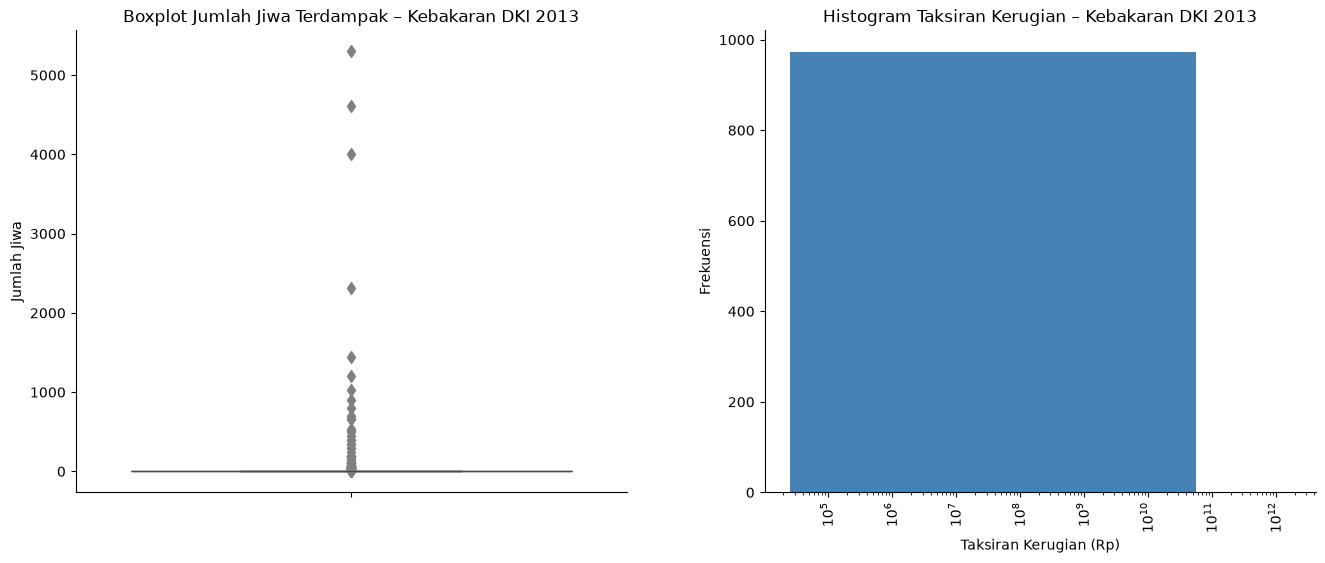

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Visualisasi 1: Boxplot Jumlah Jiwa
sns.boxplot(y=df['jumlah_jiwa'], ax=axes[0], color='steelblue', flierprops={'marker': 'd', 'markerfacecolor': 'gray', 'markeredgecolor': 'gray'})
axes[0].set_title('Boxplot Jumlah Jiwa Terdampak – Kebakaran DKI 2013')
axes[0].set_ylabel('Jumlah Jiwa')

# Visualisasi 2: Histogram Taksiran Kerugian dengan Skala Logaritmik
axes[1].hist(df['taksiran_kerugian'].dropna(), bins=30, color='steelblue')
axes[1].set_title('Histogram Taksiran Kerugian – Kebakaran DKI 2013')
axes[1].set_xlabel('Taksiran Kerugian (Rp)')
axes[1].set_ylabel('Frekuensi')
axes[1].set_xscale('log') # Skala log sumbu X

# Memutar angka pada sumbu X agar vertikal dan tidak bertabrakan
axes[1].tick_params(axis='x', rotation=90)

# Membersihkan tampilan dengan menghapus garis tepi (spines) atas dan kanan
for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Mengatur jarak antar grafik agar tidak dempet
plt.subplots_adjust(wspace=0.25)
plt.show()

In [7]:
df_clean = df.dropna(subset=['taksiran_kerugian']).copy()

df_clean = df_clean[df_clean['jumlah_jiwa'] <= 10]
df_clean = df_clean[df_clean['taksiran_kerugian'] <= 492500000]

In [8]:
fitur_numerik = ["jumlah_unit", "jumlah_sdm", "luas_area_kejadian", "jumlah_kk", "jumlah_jiwa"]
fitur_kategorikal = ["wilayah", "sebab_kejadian"]

X = df_clean[fitur_numerik + fitur_kategorikal]
y = df_clean["taksiran_kerugian"]

In [9]:
pemroses_numerik = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

pemroses_kategorikal = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

pra_pemrosesan = ColumnTransformer(
    transformers=[
        ('num', pemroses_numerik, fitur_numerik),
        ('cat', pemroses_kategorikal, fitur_kategorikal)
    ])

In [10]:
model = Pipeline(steps=[
    ('preprocessor', pra_pemrosesan),
    ('regressor', LinearRegression())
])

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [12]:
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [13]:
y_pred = model.predict(X_test)

MAE = mean_absolute_error(y_test, y_pred)
RMSE = np.sqrt(mean_squared_error(y_test, y_pred))
R2 = r2_score(y_test, y_pred)

print("Hasil Evaluasi Model:")
print(f"MAE  : Rp{MAE:,.0f}")
print(f"RMSE : Rp{RMSE:,.0f}")
print(f"R2   : {R2:.4f}")

Hasil Evaluasi Model:
MAE  : Rp54,621,758
RMSE : Rp83,096,225
R2   : 0.4187


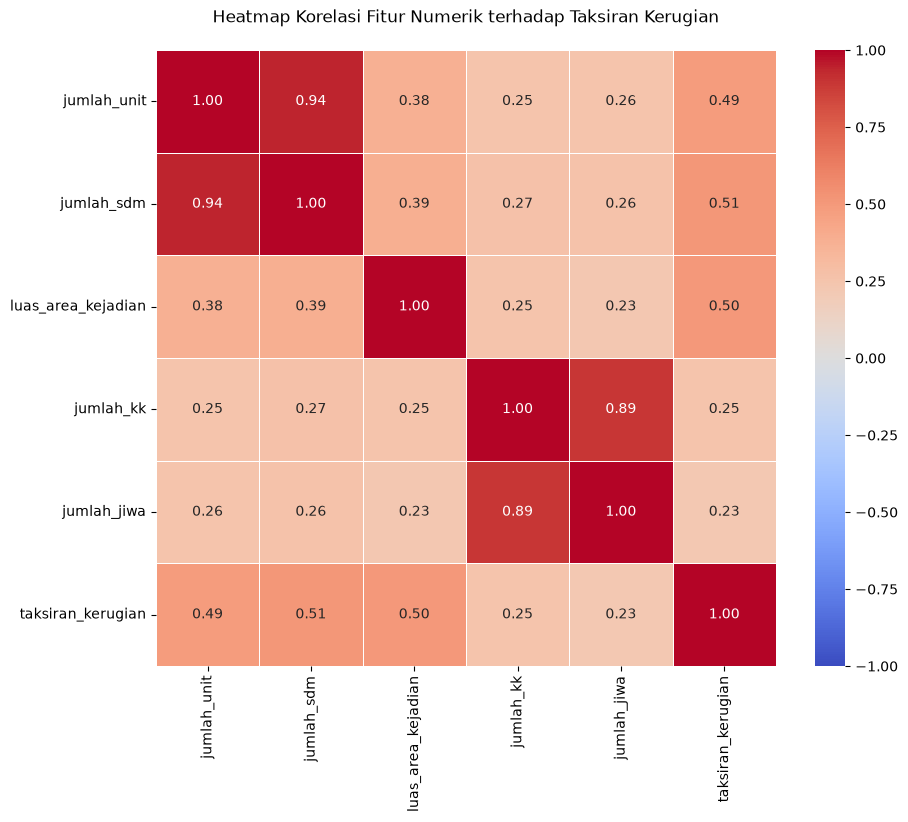

In [14]:
plt.figure(figsize=(10, 8))
kolom_korelasi = df_clean[fitur_numerik + ['taksiran_kerugian']]
matriks_korelasi = kolom_korelasi.corr()
sns.heatmap(matriks_korelasi, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)
plt.title('Heatmap Korelasi Fitur Numerik terhadap Taksiran Kerugian', pad=20)
plt.show()